# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Packages are pinned in `requirements.txt` and the interpreter in `.python-version`. The cell checks `data/dc_pm25_daily.csv` against the SHA-256 in `data/README.md` before anything is fitted. The decision rule and its costs come from `decision_rule.py`, so the notebook and the `decisions.md` loss entry use the same numbers. Nothing in this notebook depends on a random draw yet; the seed is set for the simulation check.

In [1]:
import hashlib
import platform
import re
from math import erfc, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from decision_rule import (FALSE_ALARM_COST, MISSED_BAD_AIR_COST, PM25_LIMIT,
                           decision_threshold, evaluate_cost, move_indoors)

SEED = 600
rng = np.random.default_rng(SEED)
FIG = Path("fig")
FIG.mkdir(exist_ok=True)
DATA_FILE = Path("data/dc_pm25_daily.csv")

print("Python", platform.python_version(), "| .python-version:", Path(".python-version").read_text().strip())

if not DATA_FILE.exists():
    raise FileNotFoundError("Run `gh release download data --dir data` or `python build_data.py` first.")
expected = re.search(r"SHA256:\s*([0-9a-f]{64})", Path("data/README.md").read_text())
actual = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
if expected is None or actual != expected.group(1):
    raise ValueError(f"{DATA_FILE} does not match the SHA-256 in data/README.md (file is {actual})")
print("Checksum OK:", actual)
print(f"Costs: false alarm ${FALSE_ALARM_COST}, missed bad-air day ${MISSED_BAD_AIR_COST}; "
      f"move inside when P(PM2.5 > {PM25_LIMIT}) > {decision_threshold():.2f}")

Python 3.13.18 | .python-version: 3.13.18
Checksum OK: dc43845209b3b8fa9c8c951e5e73595b9c786c17999473655184e7af6f3f1c4a
Costs: false alarm $100, missed bad-air day $900; move inside when P(PM2.5 > 35.4) > 0.10


## Question

Will tomorrow's air in Washington, DC be unhealthy enough for sensitive groups that outdoor practice should move inside? The quantity is the next calendar day's 24-hour mean PM2.5 across the District of Columbia AQS monitors, in µg/m³, forecast at 8:00 pm the evening before, for 2015 through 2024.

The decision is the athletic director's: practice inside or outside tomorrow. A false alarm (inside on a clean day) costs \$100. A miss (outside on a day above 35.4 µg/m³) costs \$900, so the miss is the costlier mistake. With $p$ the predicted probability that PM2.5 exceeds 35.4 µg/m³, the expected loss is $100(1-p)$ for moving inside and $900p$ for staying outside, so practice moves inside when $p > 100/(100+900) = 0.10$.

![Layer diagram](fig/layers.png)

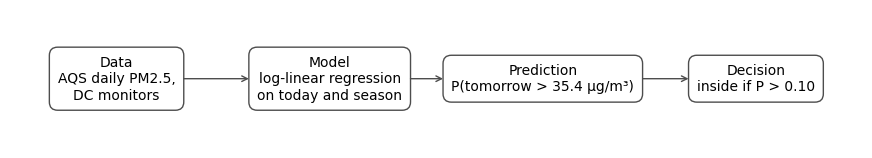

In [2]:
steps = ["Data\nAQS daily PM2.5,\nDC monitors", "Model\nlog-linear regression\non today and season",
         "Prediction\nP(tomorrow > 35.4 µg/m³)", "Decision\ninside if P > 0.10"]
fig, ax = plt.subplots(figsize=(11, 1.8))
ax.set_xlim(0, 4)
ax.set_ylim(-1, 1)
ax.axis("off")
boxes = [ax.text(i + 0.5, 0, s, ha="center", va="center", fontsize=10,
                 bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="0.3")) for i, s in enumerate(steps)]
for left, right in zip(boxes, boxes[1:]):
    ax.annotate("", xy=(0, 0.5), xycoords=right, xytext=(1, 0.5), textcoords=left,
                arrowprops=dict(arrowstyle="->", color="0.3", shrinkA=6, shrinkB=6))
fig.savefig(FIG / "layers.png", dpi=150, bbox_inches="tight")
plt.show()

## Data

Download the release into this folder:

```bash
gh release download data --dir data --repo khushisankar-dot/aii600-final-project
```

or rebuild it from EPA with `python build_data.py`. The source, the processing, and the SHA-256 are in `data/README.md`. One row is one day: the mean of the DC monitors' 24-hour mean PM2.5 (µg/m³). The plot is saved as `fig/raw_pm25.png`.

3653 days, 2015-01-01 to 2024-12-31, 1 days with no DC reading


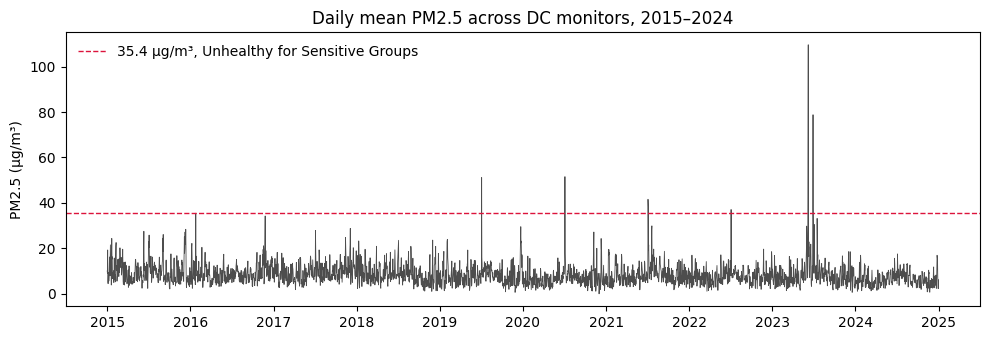

,days,mean,median,p95,max,days_over_35_4
year,,,,,,
2015,365,9.8,8.9,19.9,28.4,0
2016,366,9.1,8.3,16.5,35.5,1
2017,365,9.6,9.1,16.5,28.8,0
2018,365,8.7,8.1,17.1,23.6,0
2019,365,8.3,7.5,15.3,51.2,1
2020,366,6.9,6.3,12.7,51.6,1
2021,365,8.7,7.9,16.8,41.6,2
2022,365,7.7,7.3,14.0,37.1,1
2023,365,9.1,7.3,18.4,109.6,5


In [3]:
pm = pd.read_csv(DATA_FILE, parse_dates=["date"]).set_index("date").asfreq("D")
print(f"{len(pm)} days, {pm.index.min().date()} to {pm.index.max().date()}, "
      f"{pm['pm25'].isna().sum()} days with no DC reading")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(pm.index, pm["pm25"], lw=0.6, color="0.3")
ax.axhline(PM25_LIMIT, color="crimson", ls="--", lw=1,
           label="35.4 µg/m³, Unhealthy for Sensitive Groups")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Daily mean PM2.5 across DC monitors, 2015–2024")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "raw_pm25.png", dpi=150)
plt.show()

summary = pm.groupby(pm.index.year)["pm25"].agg(
    days="count",
    mean="mean",
    median="median",
    p95=lambda s: s.quantile(0.95),
    max="max",
    days_over_35_4=lambda s: int((s > PM25_LIMIT).sum()),
).round(1)
summary.index.name = "year"
summary

## Split

The decision is about tomorrow, so the held-out set is a later time: everything from 1 January 2022 on (2022–2024). The model is fitted on 2015–2021 only. The cutoff is recorded in `decisions.md`; there is no random draw.

Each row is a target day $d$. The inputs are known at 8:00 pm on day $d-1$: that day's reading and the mean of the seven days ending on it. Season enters through the day of the year of $d$. Days with no reading on $d$ or $d-1$ are dropped, so the baseline and the model are scored on exactly the same days.

In [4]:
CUTOFF = pd.Timestamp("2022-01-01")

df = pd.DataFrame({"y": pm["pm25"]})
df["today"] = pm["pm25"].shift(1)
df["week"] = pm["pm25"].shift(1).rolling(7, min_periods=5).mean()
angle = 2 * np.pi * df.index.dayofyear / 365.25
df["sin_season"] = np.sin(angle)
df["cos_season"] = np.cos(angle)
df = df.dropna()

train = df[df.index < CUTOFF]
test = df[df.index >= CUTOFF]
pd.DataFrame({
    "first day": [train.index.min().date(), test.index.min().date()],
    "last day": [train.index.max().date(), test.index.max().date()],
    "days": [len(train), len(test)],
    "days over 35.4": [int((train["y"] > PM25_LIMIT).sum()), int((test["y"] > PM25_LIMIT).sum())],
}, index=["train", "held out"])

,first day,last day,days,days over 35.4
train,2015-01-06,2021-12-31,2552,5
held out,2022-01-01,2024-12-31,1094,6


## Baseline

Persistence: tomorrow looks like today. The forecast for day $d$ is the reading on day $d-1$, and practice moves inside when that reading was above 35.4 µg/m³. It is scored on the held-out days in dollars with `evaluate_cost`. Never moving inside and always moving inside are shown as reference points; they bracket what any rule can cost.

In [5]:
def score(name, inside, forecast=None):
    """Held-out decision cost in dollars, plus the counts behind it."""
    inside = np.asarray(inside, dtype=bool)
    over = (test["y"] > PM25_LIMIT).to_numpy()
    return {
        "method": name,
        "cost ($)": evaluate_cost(inside, test["y"]),
        "cost per 100 days ($)": round(100 * evaluate_cost(inside, test["y"]) / len(test), 1),
        "days inside": int(inside.sum()),
        "missed bad-air days": int((~inside & over).sum()),
        "false alarms": int((inside & ~over).sum()),
        "MAE (µg/m³)": None if forecast is None else round(float(np.mean(np.abs(forecast - test["y"]))), 2),
    }

results = [
    score("Never move inside", np.zeros(len(test), bool)),
    score("Always move inside", np.ones(len(test), bool)),
    score("Persistence: tomorrow = today", test["today"] > PM25_LIMIT, test["today"]),
]
pd.DataFrame(results).set_index("method")

,cost ($),cost per 100 days ($),days inside,missed bad-air days,false alarms,MAE (µg/m³)
method,,,,,,
Never move inside,5400.0,493.6,0,6,0,NaN
Always move inside,108800.0,9945.2,1094,0,1088,NaN
Persistence: tomorrow = today,3000.0,274.2,6,3,3,2.87


## Model

For target day $d$, with $x_{d-1}$ the reading on the evening the forecast is made, $w_{d-1}$ the mean of the seven days ending then, and $t_d$ the day of the year:

$$\log y_d = \beta_0 + \beta_1 \log x_{d-1} + \beta_2 \log w_{d-1} + \beta_3 \sin\frac{2\pi t_d}{365.25} + \beta_4 \cos\frac{2\pi t_d}{365.25} + \varepsilon_d, \qquad \varepsilon_d \sim N(0, \sigma^2).$$

- $\beta_1$ is persistence: how much of today's air carries into tomorrow, because the air mass and the weather that trapped it usually last more than a day.
- $\beta_2$ is the slower background level of the past week, which pulls a one-day spike back toward the recent normal.
- $\beta_3, \beta_4$ are the seasonal cycle: summer heat and stagnation, and winter inversions and wood smoke.
- $\beta_0$ sets the overall level, and $\sigma$ is the day-to-day surprise on the log scale.

Working on the log scale makes the effects multiplicative and keeps forecasts positive. The prediction is a full distribution: $y_d$ is lognormal, so

$$P(y_d > 35.4) = 1 - \Phi\!\left(\frac{\log 35.4 - \mu_d}{\sigma}\right),$$

with $\mu_d$ the fitted mean of $\log y_d$. The point forecast is the median $e^{\mu_d}$, with an 80% interval $e^{\mu_d \pm 1.28\sigma}$. The assumption we trust least is a constant, normal $\sigma$: smoke from wildfires arrives suddenly and is heavier-tailed than a normal on the log scale, so the model will understate the probability on the first day of a smoke event. The model is fitted by least squares on 2015–2021 and scored on the same held-out days as the baseline.

In [6]:
def design(d):
    return np.column_stack([
        np.ones(len(d)),
        np.log(d["today"].clip(lower=0.5)),
        np.log(d["week"].clip(lower=0.5)),
        d["sin_season"],
        d["cos_season"],
    ])

X_train = design(train)
y_train = np.log(train["y"].clip(lower=0.5)).to_numpy()
beta, *_ = np.linalg.lstsq(X_train, y_train, rcond=None)
resid = y_train - X_train @ beta
sigma = float(np.sqrt(resid @ resid / (len(y_train) - X_train.shape[1])))
se = np.sqrt(np.diag(sigma**2 * np.linalg.inv(X_train.T @ X_train)))

names = ["β0 intercept", "β1 log today", "β2 log 7-day mean", "β3 sin season", "β4 cos season"]
display(pd.DataFrame({"estimate": beta, "std. error": se}, index=names).round(3))
print(f"σ = {sigma:.3f} on the log scale (a typical surprise of ×{np.exp(sigma):.2f})")

def prob_over(mu, limit=PM25_LIMIT):
    z = (np.log(limit) - mu) / sigma
    return np.array([0.5 * erfc(v / sqrt(2)) for v in z])

mu = design(test) @ beta
test = test.assign(
    median=np.exp(mu),
    lo80=np.exp(mu - 1.2816 * sigma),
    hi80=np.exp(mu + 1.2816 * sigma),
    p_over=prob_over(mu),
)
test["inside"] = move_indoors(test["p_over"].to_numpy())

results.append(score("Log-linear model, inside if P > 0.10", test["inside"], test["median"]))
held_out = pd.DataFrame(results).set_index("method")
held_out

,estimate,std. error
β0 intercept,0.778,0.058
β1 log today,0.535,0.019
β2 log 7-day mean,0.081,0.032
β3 sin season,-0.015,0.012
β4 cos season,-0.025,0.012


σ = 0.420 on the log scale (a typical surprise of ×1.52)


,cost ($),cost per 100 days ($),days inside,missed bad-air days,false alarms,MAE (µg/m³)
method,,,,,,
Never move inside,5400.0,493.6,0,6,0,NaN
Always move inside,108800.0,9945.2,1094,0,1088,NaN
Persistence: tomorrow = today,3000.0,274.2,6,3,3,2.87
"Log-linear model, inside if P > 0.10",3700.0,338.2,3,4,1,2.54


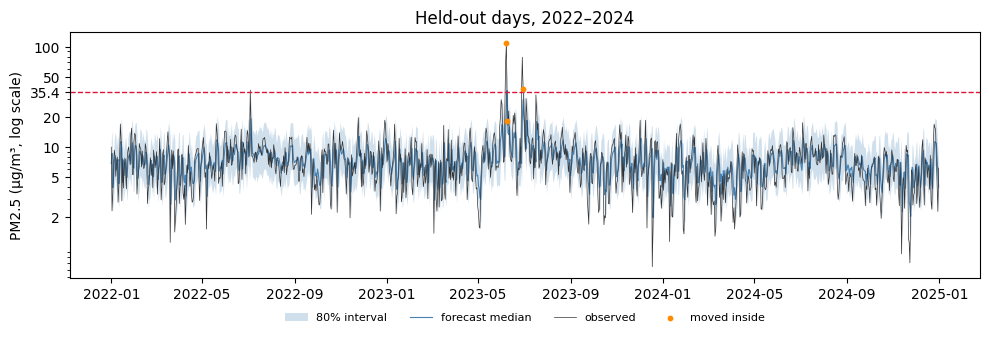

Over 1094 held-out days the model's decisions cost $700 more than persistence.


In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between(test.index, test["lo80"], test["hi80"], color="steelblue", alpha=0.25, lw=0, label="80% interval")
ax.plot(test.index, test["median"], color="steelblue", lw=0.8, label="forecast median")
ax.plot(test.index, test["y"], color="0.2", lw=0.5, label="observed")
ax.axhline(PM25_LIMIT, color="crimson", ls="--", lw=1)
inside = test[test["inside"]]
ax.scatter(inside.index, inside["y"], s=10, color="darkorange", zorder=3, label="moved inside")
ax.set_yscale("log")
ticks = [2, 5, 10, 20, PM25_LIMIT, 50, 100]
ax.set_yticks([t for t in ticks if t <= max(test["y"].max(), test["hi80"].max()) * 1.2])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("PM2.5 (µg/m³, log scale)")
ax.set_title("Held-out days, 2022–2024")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "heldout_forecast.png", dpi=150)
plt.show()

saving = held_out.loc["Persistence: tomorrow = today", "cost ($)"] - held_out.loc["Log-linear model, inside if P > 0.10", "cost ($)"]
print(f"Over {len(test)} held-out days the model's decisions cost ${abs(saving):,.0f} "
      f"{'less' if saving >= 0 else 'more'} than persistence.")

## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
